<a href="https://colab.research.google.com/github/Twishha-Soni/MakeMore/blob/main/Makemore_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import math
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
import torch
%matplotlib inline

In [2]:
words = open('names.txt', 'r').read().splitlines()
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [3]:
len(words)

32033

In [4]:
min(len(w) for w in words)

2

In [5]:
max(len(w) for w in words)

15

In [6]:
b = {}
for w in words:
  chs = ['<S>'] + list(w) + ['<E>']
  for ch1, ch2 in zip(chs, chs[1:]):
    bigram = (ch1, ch2)
    b[bigram] = b.get(bigram, 0) + 1

In [7]:
sorted(b.items(), key=lambda x: -x[1])

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [8]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i for i, s in enumerate(chars, start=1)}
stoi.update({'.': 0})
itos = {i:s for s, i in stoi.items()}

In [9]:
N = torch.zeros((27,27), dtype=torch.int32)
for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    N[stoi[ch1]][stoi[ch2]] += 1

(np.float64(-0.5), np.float64(26.5), np.float64(26.5), np.float64(-0.5))

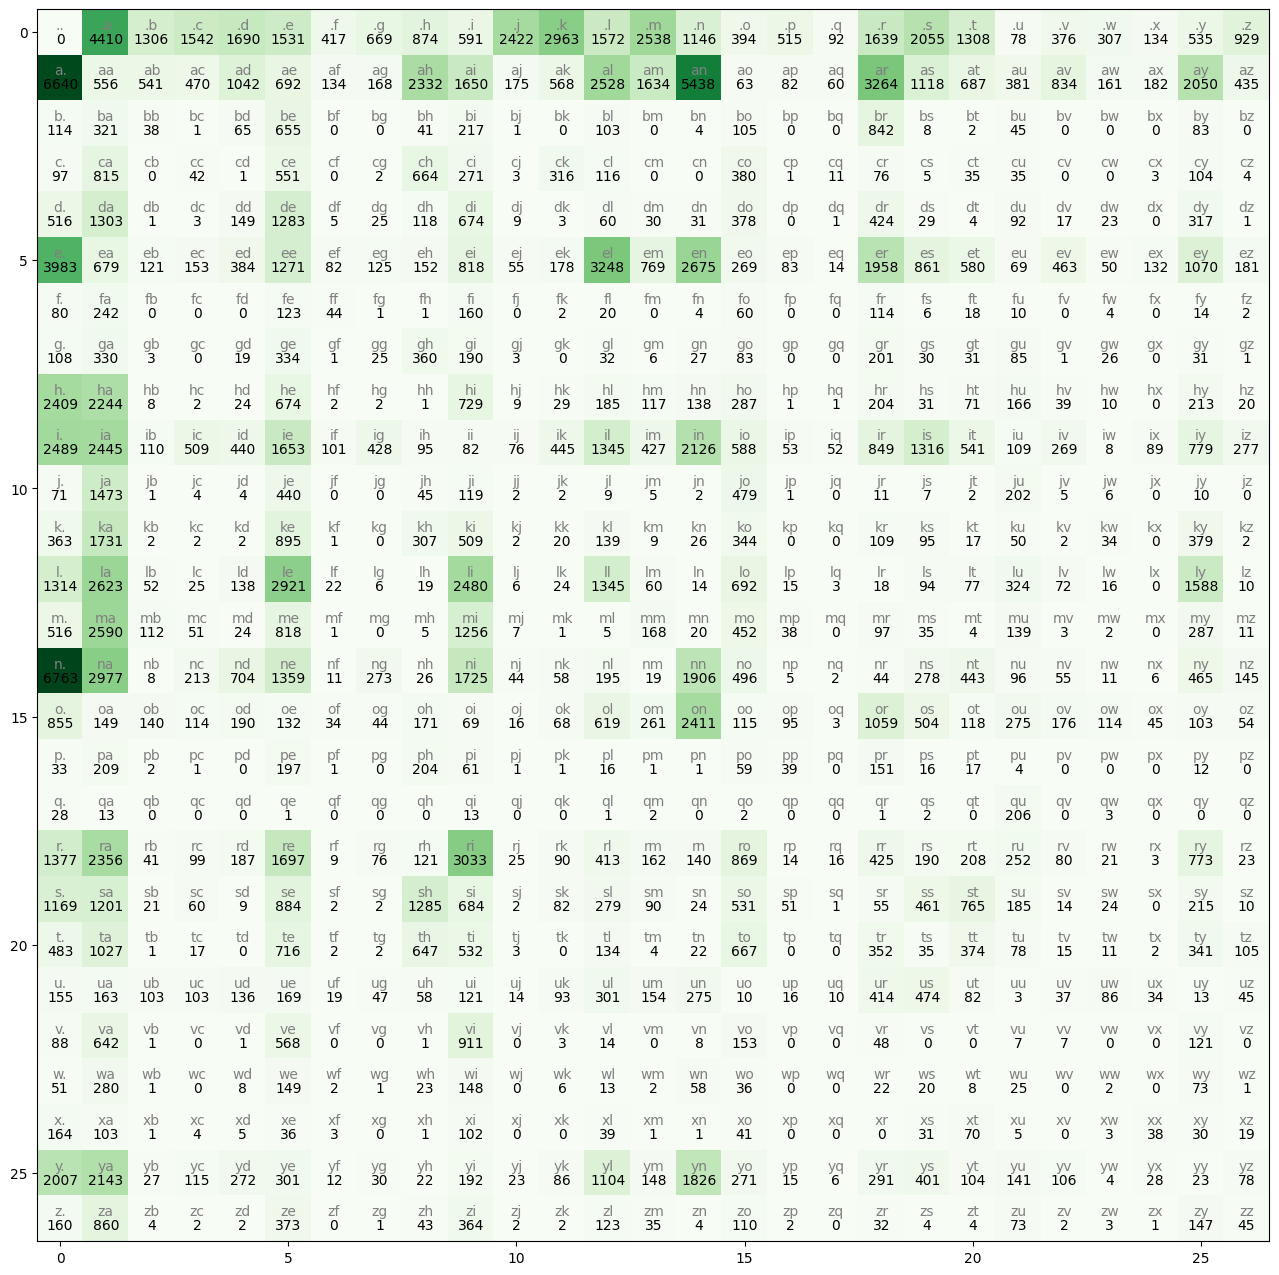

In [10]:
plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Greens')
for i in range(27):
  for j in range(27):
    chstr = itos[i] + itos[j]
    plt.text(j, i, chstr, ha='center', va='bottom', color='gray')
    plt.text(j, i, N[i, j].item(), ha='center', va='top', color='black')
plt.axis()

In [11]:
P = (N+1).float()  # model smoothing to avoid - inf when the log of something 0 will be -inf
P /= P.sum(1, keepdim=True) # this operation of (27, 27) / (27, 1) is broadcastable

In [12]:
g = torch.Generator().manual_seed(42)

for i in range(50):
  name = []
  ix = 0
  while True:
    p = P[ix]
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    if ix == 0:
      break
    name.append(itos[ix])

  print("".join(name))

anugeenvi
s
mabidushan
stan
silaylelaremah
li
le
epiachalen
diza
k
ach
jondry
kanla
miqulynaya
visigea
zalamitiare
phalimasotal
selaro
dgharoni
n
anncrrigh
dyn
sor
payiewo
liljahm
fri
bradon
an
krok
feliavaham
anone
brral
cdo
t
damayanel
ritaha
iriatla
ka
mouchaame
josky
loraachan
mooriaya
hluli
b
th
lykamiseysh
endh
n
kue
enoniahilln


In [13]:
# log(a*b*c) = log(a) + log(b) + log(c)
# where a,b,c are prob.

# normalize is nothing but kind of average.

In [14]:
log_likelihood = 0.0
n = 0

for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    prob = P[ix1][ix2]
    logprob = torch.log(prob)
    log_likelihood += logprob
    n += 1
    # print(f"{ch1}{ch2}: {prob:.4f} {logprob:.4f}")
    # log(x) -> 0 if x -> increase
    # log(x) -> -inf if x -> 0

In [15]:
neg_log_likelihood = -log_likelihood
normalized_nll = neg_log_likelihood / n

print(f'{log_likelihood=}')
print(f'{neg_log_likelihood=}')
print(f'{normalized_nll=}')
# because what we consider loss function is something higher which we tend to lower
# so when prob are equal to 1, the log tends to 0
# but if there are lower prob, the log would be -ve and summation of this will be high -ve.

log_likelihood=tensor(-559951.5625)
neg_log_likelihood=tensor(559951.5625)
normalized_nll=tensor(2.4544)


In [16]:
# GOAL: maximize the likelihood(individual prob) of the data wrt model parameters
# equivalent to maximizing the log likelihood
# equivalent to minimizing the negative log likelihood
# equivalent to minimizing the average negative log likelihood.

In [17]:
# ---------------- !!! TRAINING THROUGH NEURAL NETWORK !!! -----------------

In [18]:
# create the training set for all the bigrams for neural network
# input - first character
# target - second character after 1st using prob.
xs, ys = [], []

for w in words[:1]:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    xs.append(ix1)
    ys.append(ix2)
    print(f"{ch1} {ch2}")


xs = torch.tensor(xs)
ys = torch.tensor(ys)
print(f"{xs=}")
print(f"{ys=}")

. e
e m
m m
m a
a .
xs=tensor([ 0,  5, 13, 13,  1])
ys=tensor([ 5, 13, 13,  1,  0])


In [19]:
import torch.nn.functional as F

xenc = F.one_hot(xs, num_classes=27).float()
xenc

tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.]])

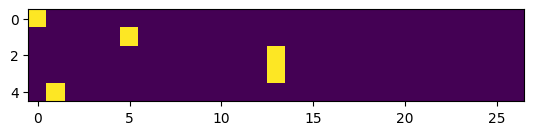

In [20]:
plt.imshow(xenc)

In [21]:
xenc.dtype

torch.float32

In [22]:
w = torch.randn((27,27), generator=g)
xenc @ w
# (5, 27) @ (27, 27)

tensor([[-9.7106e-01,  2.1073e-01, -6.3664e-01,  9.3753e-01, -1.5073e+00,
          2.4299e-01,  2.1263e-01, -4.6831e-01,  1.5708e+00,  1.1971e+00,
         -1.1117e+00, -1.5615e+00, -7.2321e-01,  1.1031e+00,  6.3114e-02,
         -2.2738e+00,  1.1571e+00, -1.7841e+00,  5.6453e-02,  3.8664e-01,
          1.4421e+00, -9.0072e-01, -1.0348e+00, -1.8648e-01,  9.5343e-01,
         -8.9883e-02,  3.5554e+00],
        [ 1.3819e-01,  4.5762e-01,  3.3388e-01,  1.2617e+00, -4.6433e-01,
          1.9130e-01,  9.2725e-01,  1.0973e+00,  2.3370e+00,  1.4305e+00,
          4.0470e-01, -3.6815e-01,  5.9587e-01, -1.6833e-01, -8.4278e-02,
          2.7247e-01,  8.4226e-01,  2.5072e+00, -1.6278e+00,  4.6814e-01,
          5.6077e-01,  1.1339e+00,  6.3809e-01,  4.3179e-01,  2.2817e+00,
          9.5283e-01,  7.3053e-01],
        [ 5.1922e-02, -3.0990e-01, -1.2903e+00,  8.6587e-01, -2.4198e-01,
         -9.4362e-01, -1.0791e-01, -1.0269e-01,  3.3307e-01,  1.5542e-01,
         -2.5826e+00,  1.1090e-03,  1.22

In [23]:
logits = xenc @ w  # log-counts
counts = logits.exp() # equivalent to N (count array for (ch1, ch2))
prob = counts / counts.sum(1, keepdim=True) # (5, 27) / (5, 1)
prob  # equivalent to N (prob)

tensor([[0.0053, 0.0172, 0.0074, 0.0357, 0.0031, 0.0178, 0.0173, 0.0087, 0.0672,
         0.0462, 0.0046, 0.0029, 0.0068, 0.0421, 0.0149, 0.0014, 0.0444, 0.0023,
         0.0148, 0.0206, 0.0591, 0.0057, 0.0050, 0.0116, 0.0362, 0.0128, 0.4889],
        [0.0152, 0.0209, 0.0184, 0.0466, 0.0083, 0.0160, 0.0334, 0.0395, 0.1366,
         0.0552, 0.0198, 0.0091, 0.0239, 0.0112, 0.0121, 0.0173, 0.0306, 0.1619,
         0.0026, 0.0211, 0.0231, 0.0410, 0.0250, 0.0203, 0.1292, 0.0342, 0.0274],
        [0.0264, 0.0184, 0.0069, 0.0596, 0.0197, 0.0098, 0.0225, 0.0226, 0.0350,
         0.0293, 0.0019, 0.0251, 0.0283, 0.0572, 0.0424, 0.0173, 0.0158, 0.0903,
         0.0147, 0.0062, 0.0139, 0.0182, 0.0053, 0.0613, 0.3153, 0.0241, 0.0128],
        [0.0264, 0.0184, 0.0069, 0.0596, 0.0197, 0.0098, 0.0225, 0.0226, 0.0350,
         0.0293, 0.0019, 0.0251, 0.0283, 0.0572, 0.0424, 0.0173, 0.0158, 0.0903,
         0.0147, 0.0062, 0.0139, 0.0182, 0.0053, 0.0613, 0.3153, 0.0241, 0.0128],
        [0.0619, 0.0423,

In [24]:
nlls = torch.zeros(5)

for i in range(5):
  x = xs[i].item()
  y = ys[i].item()
  print("-------------")
  print(f"bigram example {i+1}: {itos[x]}{itos[y]} (indexes {x},{y})")
  print(f"input to the neural net:", x)
  print(f"output probabilities from the neural net:", prob[i])
  print(f"label (actual next character): ", itos[y], f"index ({y})")
  p = prob[i, y]
  print('probability assigned by the net to the correct character:', p.item())
  logp = torch.log(p)
  print('log likelihood:', logp.item())
  nll = -logp
  print('negative log likelihood:', nll.item())
  nlls[i] = nll


-------------
bigram example 1: .e (indexes 0,5)
input to the neural net: 0
output probabilities from the neural net: tensor([0.0053, 0.0172, 0.0074, 0.0357, 0.0031, 0.0178, 0.0173, 0.0087, 0.0672,
        0.0462, 0.0046, 0.0029, 0.0068, 0.0421, 0.0149, 0.0014, 0.0444, 0.0023,
        0.0148, 0.0206, 0.0591, 0.0057, 0.0050, 0.0116, 0.0362, 0.0128, 0.4889])
label (actual next character):  e index (5)
probability assigned by the net to the correct character: 0.017810093238949776
log likelihood: -4.027989864349365
negative log likelihood: 4.027989864349365
-------------
bigram example 2: em (indexes 5,13)
input to the neural net: 5
output probabilities from the neural net: tensor([0.0152, 0.0209, 0.0184, 0.0466, 0.0083, 0.0160, 0.0334, 0.0395, 0.1366,
        0.0552, 0.0198, 0.0091, 0.0239, 0.0112, 0.0121, 0.0173, 0.0306, 0.1619,
        0.0026, 0.0211, 0.0231, 0.0410, 0.0250, 0.0203, 0.1292, 0.0342, 0.0274])
label (actual next character):  m index (13)
probability assigned by the net to 

In [25]:
print('average negative log likelihood, i.e. loss:', nlls.mean().item())

average negative log likelihood, i.e. loss: 3.6328110694885254


In [26]:
# ---------- OPTIMIZATION -------------

In [27]:
xs, ys = [], []

for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    xs.append(ix1)
    ys.append(ix2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()
print('number of examples: ', num)

# randomly initialize 27 neurons' weights. Each neuron receives 27 weights
g = torch.Generator().manual_seed(42)
W = torch.randn((27, 27), generator=g, requires_grad=True)

number of examples:  228146


In [67]:
for i in range(20):
  # forward pass
  xenc = F.one_hot(xs, num_classes=27).float()
  logits = xenc @ W
  counts = logits.exp()
  prob = counts / counts.sum(1, keepdim=True)
  loss = -prob[torch.arange(num), ys].log().mean() + 0.01 * (W**2).mean()

  # backward pass
  W.grad = None # set to zero the gradient
  loss.backward()

  # update the weights
  W.data += -5.1 * W.grad

print(f"{loss=}")

loss=tensor(2.5520, grad_fn=<AddBackward0>)


In [68]:
# finally, sample from the 'neural net' model
g = torch.Generator().manual_seed(42)

for i in range(5):

  out = []
  ix = 0
  while True:
    # ----------
    # BEFORE:
    # p = P[ix]
    # ----------

    # NOW:
    xenc = F.one_hot(torch.tensor([ix]), num_classes=27).float()
    logits = xenc @ W
    counts = logits.exp()
    p = counts / counts.sum(1, keepdim=True)
    # ------------

    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    out.append(itos[ix])
    if ix == 0:
      break
  print("".join(out))

anugeenvt.
s.
mabidushxfmuben.
silaylelaremah.
li.
